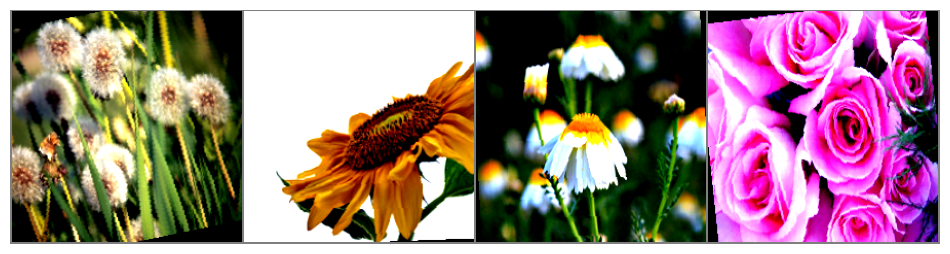

Batch Image Shape : torch.Size([32, 3, 224, 224])
Batch Labels Shape: torch.Size([32])
Sample Labels     : ['Class_1', 'Class_3', 'Class_0', 'Class_2']


In [31]:
import matplotlib.pyplot as plt
import torchvision
import numpy as np

# 1. Get a single batch of training data from your DataLoader
# Replace 'train_loader' with your actual DataLoader variable name if different
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Define your class names (update these to match your actual 5 dataset classes)
class_names = ['Class_0', 'Class_1', 'Class_2', 'Class_3', 'Class_4']

# 2. Function to un-normalize and convert tensor to printable image format
def imshow(img):
    img = img / 2 + 0.5  # Un-normalize if standard normalization was applied
    npimg = img.numpy()
    plt.figure(figsize=(12, 6))
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')
    plt.show()

# 3. Create a grid of sample images (displays up to 4 or 8 images)
grid_img = torchvision.utils.make_grid(images[:4])
imshow(grid_img)

# 4. Print tensor shapes and target labels
print("Batch Image Shape :", images.shape)      # Expecting [Batch_Size, Channels, Height, Width]
print("Batch Labels Shape:", labels.shape)      # Expecting [Batch_Size]
print("Sample Labels     :", [class_names[l] for l in labels[:4].tolist()])

In [24]:
import torch
import torch.nn as nn
import torchvision.models as models

class ResNet50Baseline(nn.Module):
    def __init__(self, num_classes=5):
        super(ResNet50Baseline, self).__init__()
        # Load ImageNet Pretrained ResNet50
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1 # P1 (56x56, 256)
        self.layer2 = resnet.layer2 # P2 (28x28, 512)
        self.layer3 = resnet.layer3 # P3 (14x14, 1024)
        self.layer4 = resnet.layer4 # P4 (7x7, 2048)

        self.avgpool = resnet.avgpool
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

if __name__ == "__main__":
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = ResNet50Baseline(num_classes=5).to(device)
    x = torch.randn(2, 3, 224, 224).to(device)
    out = model(x)
    print(f"Baseline output shape: {out.shape}") # Expect [2, 5]

Baseline output shape: torch.Size([2, 5])


In [23]:
import torch
import torch.nn as nn
import torchvision.models as models

class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y.expand_as(x)

class ResNet50ChannelP3(nn.Module):
    def __init__(self, num_classes=5):
        super(ResNet50ChannelP3, self).__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3 # P3
        self.ca_p3 = ChannelAttention(1024, reduction=16)
        self.layer4 = resnet.layer4
        self.avgpool = resnet.avgpool
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.ca_p3(x) # Attention at P3
        x = self.layer4(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

if __name__ == "__main__":
    model = ResNet50ChannelP3()
    x = torch.randn(2, 3, 224, 224)
    print(f"Channel Attention P3 output shape: {model(x).shape}")

Channel Attention P3 output shape: torch.Size([2, 5])


In [22]:
import torch
import torch.nn as nn
import torchvision.models as models

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()
        padding = kernel_size // 2
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        scale = torch.cat([avg_out, max_out], dim=1)
        scale = self.conv(scale)
        return x * self.sigmoid(scale)

class ResNet50SpatialP3(nn.Module):
    def __init__(self, num_classes=5):
        super(ResNet50SpatialP3, self).__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.sa_p3 = SpatialAttention(kernel_size=7)
        self.layer4 = resnet.layer4
        self.avgpool = resnet.avgpool
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x); x = self.layer2(x)
        x = self.layer3(x)
        x = self.sa_p3(x) # Spatial Attention at P3
        x = self.layer4(x)
        x = self.avgpool(x)
        return self.fc(torch.flatten(x, 1))

if __name__ == "__main__":
    model = ResNet50SpatialP3()
    x = torch.randn(2, 3, 224, 224)
    print(f"Spatial Attention P3 output shape: {model(x).shape}")

Spatial Attention P3 output shape: torch.Size([2, 5])


In [21]:
import torch
import torch.nn as nn
import torchvision.models as models

class CBAMBlock(nn.Module):
    def __init__(self, channels, reduction=16, kernel_size=7):
        super(CBAMBlock, self).__init__()
        # Channel Attention
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False)
        )
        self.ca_sigmoid = nn.Sigmoid()
        # Spatial Attention
        padding = kernel_size // 2
        self.sp_conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=padding, bias=False)
        self.sa_sigmoid = nn.Sigmoid()

    def forward(self, x):
        b, c, h, w = x.size()
        avg_p = torch.mean(x, dim=[2, 3])
        max_p, _ = torch.max(x.view(b, c, -1), dim=2)
        c_attn = self.ca_sigmoid(self.fc(avg_p) + self.fc(max_p)).view(b, c, 1, 1)
        x_c = x * c_attn

        avg_s = torch.mean(x_c, dim=1, keepdim=True)
        max_s, _ = torch.max(x_c, dim=1, keepdim=True)
        s_attn = self.sa_sigmoid(self.sp_conv(torch.cat([avg_s, max_s], dim=1)))
        return x_c * s_attn

class ResNet50CBAMP3(nn.Module):
    def __init__(self, num_classes=5):
        super(ResNet50CBAMP3, self).__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.cbam_p3 = CBAMBlock(1024)
        self.layer4 = resnet.layer4
        self.avgpool = resnet.avgpool
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.stem(x); x = self.layer1(x); x = self.layer2(x)
        x = self.layer3(x)
        x = self.cbam_p3(x) # Channel + Spatial at P3
        x = self.layer4(x)
        x = self.avgpool(x)
        return self.fc(torch.flatten(x, 1))

if __name__ == "__main__":
    model = ResNet50CBAMP3()
    x = torch.randn(2, 3, 224, 224)
    print(f"CBAM at P3 output shape: {model(x).shape}")

CBAM at P3 output shape: torch.Size([2, 5])


In [20]:
import torch
import torch.nn as nn
import torchvision.models as models

class CBAMBlock(nn.Module):
    def __init__(self, channels):
        super(CBAMBlock, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // 16, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // 16, channels, bias=False)
        )
        self.ca_sig = nn.Sigmoid()
        self.sp_conv = nn.Conv2d(2, 1, kernel_size=7, padding=3, bias=False)
        self.sa_sig = nn.Sigmoid()

    def forward(self, x):
        b, c, _, _ = x.size()
        avg_p = torch.mean(x, dim=[2, 3])
        x = x * self.ca_sig(self.fc(avg_p)).view(b, c, 1, 1)
        avg_s = torch.mean(x, dim=1, keepdim=True)
        max_s, _ = torch.max(x, dim=1, keepdim=True)
        return x * self.sa_sig(self.sp_conv(torch.cat([avg_s, max_s], dim=1)))

class ResNet50CBAMP2(nn.Module):
    def __init__(self, num_classes=5):
        super(ResNet50CBAMP2, self).__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2 # P2
        self.cbam_p2 = CBAMBlock(512) # 512 channels at P2
        self.layer3 = resnet.layer3
        self.layer4 = resnet.layer4
        self.avgpool = resnet.avgpool
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.stem(x); x = self.layer1(x)
        x = self.layer2(x)
        x = self.cbam_p2(x) # Inserted at P2
        x = self.layer3(x); x = self.layer4(x)
        return self.fc(torch.flatten(self.avgpool(x), 1))

if __name__ == "__main__":
    model = ResNet50CBAMP2()
    x = torch.randn(2, 3, 224, 224)
    print(f"CBAM at P2 output shape: {model(x).shape}")

CBAM at P2 output shape: torch.Size([2, 5])


In [19]:
import torch
import torch.nn as nn
import torchvision.models as models

class CBAMBlock(nn.Module):
    def __init__(self, channels):
        super(CBAMBlock, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // 16, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // 16, channels, bias=False)
        )
        self.ca_sig = nn.Sigmoid()
        self.sp_conv = nn.Conv2d(2, 1, kernel_size=7, padding=3, bias=False)
        self.sa_sig = nn.Sigmoid()

    def forward(self, x):
        b, c, _, _ = x.size()
        avg_p = torch.mean(x, dim=[2, 3])
        x = x * self.ca_sig(self.fc(avg_p)).view(b, c, 1, 1)
        avg_s = torch.mean(x, dim=1, keepdim=True)
        max_s, _ = torch.max(x, dim=1, keepdim=True)
        return x * self.sa_sig(self.sp_conv(torch.cat([avg_s, max_s], dim=1)))

class ResNet50CBAMP4(nn.Module):
    def __init__(self, num_classes=5):
        super(ResNet50CBAMP4, self).__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.layer4 = resnet.layer4 # P4
        self.cbam_p4 = CBAMBlock(2048) # 2048 channels at P4
        self.avgpool = resnet.avgpool
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.stem(x); x = self.layer1(x); x = self.layer2(x); x = self.layer3(x)
        x = self.layer4(x)
        x = self.cbam_p4(x) # Inserted at P4
        return self.fc(torch.flatten(self.avgpool(x), 1))

if __name__ == "__main__":
    model = ResNet50CBAMP4()
    x = torch.randn(2, 3, 224, 224)
    print(f"CBAM at P4 output shape: {model(x).shape}")

CBAM at P4 output shape: torch.Size([2, 5])


In [18]:
import torch
import torch.nn as nn
import torchvision.models as models

class SelfAttentionBlock(nn.Module):
    def __init__(self, in_dim):
        super(SelfAttentionBlock, self).__init__()
        self.query_conv = nn.Conv2d(in_dim, in_dim // 8, kernel_size=1)
        self.key_conv   = nn.Conv2d(in_dim, in_dim // 8, kernel_size=1)
        self.value_conv = nn.Conv2d(in_dim, in_dim, kernel_size=1)
        self.gamma      = nn.Parameter(torch.zeros(1))
        self.softmax    = nn.Softmax(dim=-1)

    def forward(self, x):
        batch, C, width, height = x.size()
        proj_query = self.query_conv(x).view(batch, -1, width * height).permute(0, 2, 1)
        proj_key   = self.key_conv(x).view(batch, -1, width * height)
        energy     = torch.bmm(proj_query, proj_key) / ((C // 8) ** 0.5)
        attention  = self.softmax(energy)

        proj_value = self.value_conv(x).view(batch, -1, width * height)
        out        = torch.bmm(proj_value, attention.permute(0, 2, 1))
        out        = out.view(batch, C, width, height)

        return self.gamma * out + x

class ResNet50SelfAttentionP3(nn.Module):
    def __init__(self, num_classes=5):
        super(ResNet50SelfAttentionP3, self).__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1; self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.sa_p3 = SelfAttentionBlock(1024)
        self.layer4 = resnet.layer4
        self.avgpool = resnet.avgpool
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.stem(x); x = self.layer1(x); x = self.layer2(x)
        x = self.layer3(x)
        x = self.sa_p3(x) # Self-Attention at P3
        x = self.layer4(x)
        return self.fc(torch.flatten(self.avgpool(x), 1))

if __name__ == "__main__":
    model = ResNet50SelfAttentionP3()
    x = torch.randn(2, 3, 224, 224)
    print(f"Self Attention P3 output shape: {model(x).shape}")

Self Attention P3 output shape: torch.Size([2, 5])


In [17]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_image, class_idx=None):
        self.model.eval()
        output = self.model(input_image)

        if class_idx is None:
            class_idx = torch.argmax(output, dim=1).item()

        self.model.zero_grad()
        score = output[0, class_idx]
        score.backward()

        gradients = self.gradients.data.cpu().numpy()[0]
        activations = self.activations.data.cpu().numpy()[0]

        weights = np.mean(gradients, axis=(1, 2))
        cam = np.zeros(activations.shape[1:], dtype=np.float32)

        for i, w in enumerate(weights):
            cam += w * activations[i]

        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (224, 224))
        cam = cam - np.min(cam)
        cam = cam / (np.max(cam) + 1e-8)
        return cam

if __name__ == "__main__":
    from torchvision.models import resnet50, ResNet50_Weights
    model = resnet50(weights=ResNet50_Weights.DEFAULT)
    target_layer = model.layer4[-1] # Target last layer

    cam_generator = GradCAM(model, target_layer)
    dummy_img = torch.randn(1, 3, 224, 224, requires_grad=True)
    heatmap = cam_generator.generate_heatmap(dummy_img)
    print(f"Generated Grad-CAM map shape: {heatmap.shape}, Range: [{heatmap.min():.2f}, {heatmap.max():.2f}]")

Generated Grad-CAM map shape: (224, 224), Range: [0.00, 1.00]


In [30]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SpatialAttentionExtractor(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttentionExtractor, self).__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=kernel_size//2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        scale = torch.cat([avg_out, max_out], dim=1)
        attn_map = self.sigmoid(self.conv(scale))
        return attn_map

def visualize_multistage_attention():
    sa_p2 = SpatialAttentionExtractor()
    sa_p3 = SpatialAttentionExtractor()
    sa_p4 = SpatialAttentionExtractor()

    # Feature representations at P2 (28x28), P3 (14x14), P4 (7x7)
    f_p2 = torch.randn(1, 512, 28, 28)
    f_p3 = torch.randn(1, 1024, 14, 14)
    f_p4 = torch.randn(1, 2048, 7, 7)

    map_p2 = F.interpolate(sa_p2(f_p2), size=(224, 224), mode='bilinear', align_corners=False)
    map_p3 = F.interpolate(sa_p3(f_p3), size=(224, 224), mode='bilinear', align_corners=False)
    map_p4 = F.interpolate(sa_p4(f_p4), size=(224, 224), mode='bilinear', align_corners=False)

    print(f"Visual Maps Resized to 224x224:")
    print(f"P2 Map Shape: {map_p2.shape}")
    print(f"P3 Map Shape: {map_p3.shape}")
    print(f"P4 Map Shape: {map_p4.shape}")

if __name__ == "__main__":
    visualize_multistage_attention()

Visual Maps Resized to 224x224:
P2 Map Shape: torch.Size([1, 1, 224, 224])
P3 Map Shape: torch.Size([1, 1, 224, 224])
P4 Map Shape: torch.Size([1, 1, 224, 224])


/tmp/ipykernel_1091/1450047047.py:26: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df_results, x='Attention_Type', y='Val_Accuracy', ax=axes[0, 0], palette='viridis', ci=None)
/tmp/ipykernel_1091/1450047047.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_results, x='Attention_Type', y='Val_Accuracy', ax=axes[0, 0], palette='viridis', ci=None)
/tmp/ipykernel_1091/1450047047.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cbam_df, x='Position', y='Val_Accuracy', ax=axes[0, 1], palette='magma')
/tmp/ipykernel_1091/1450047047.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated 

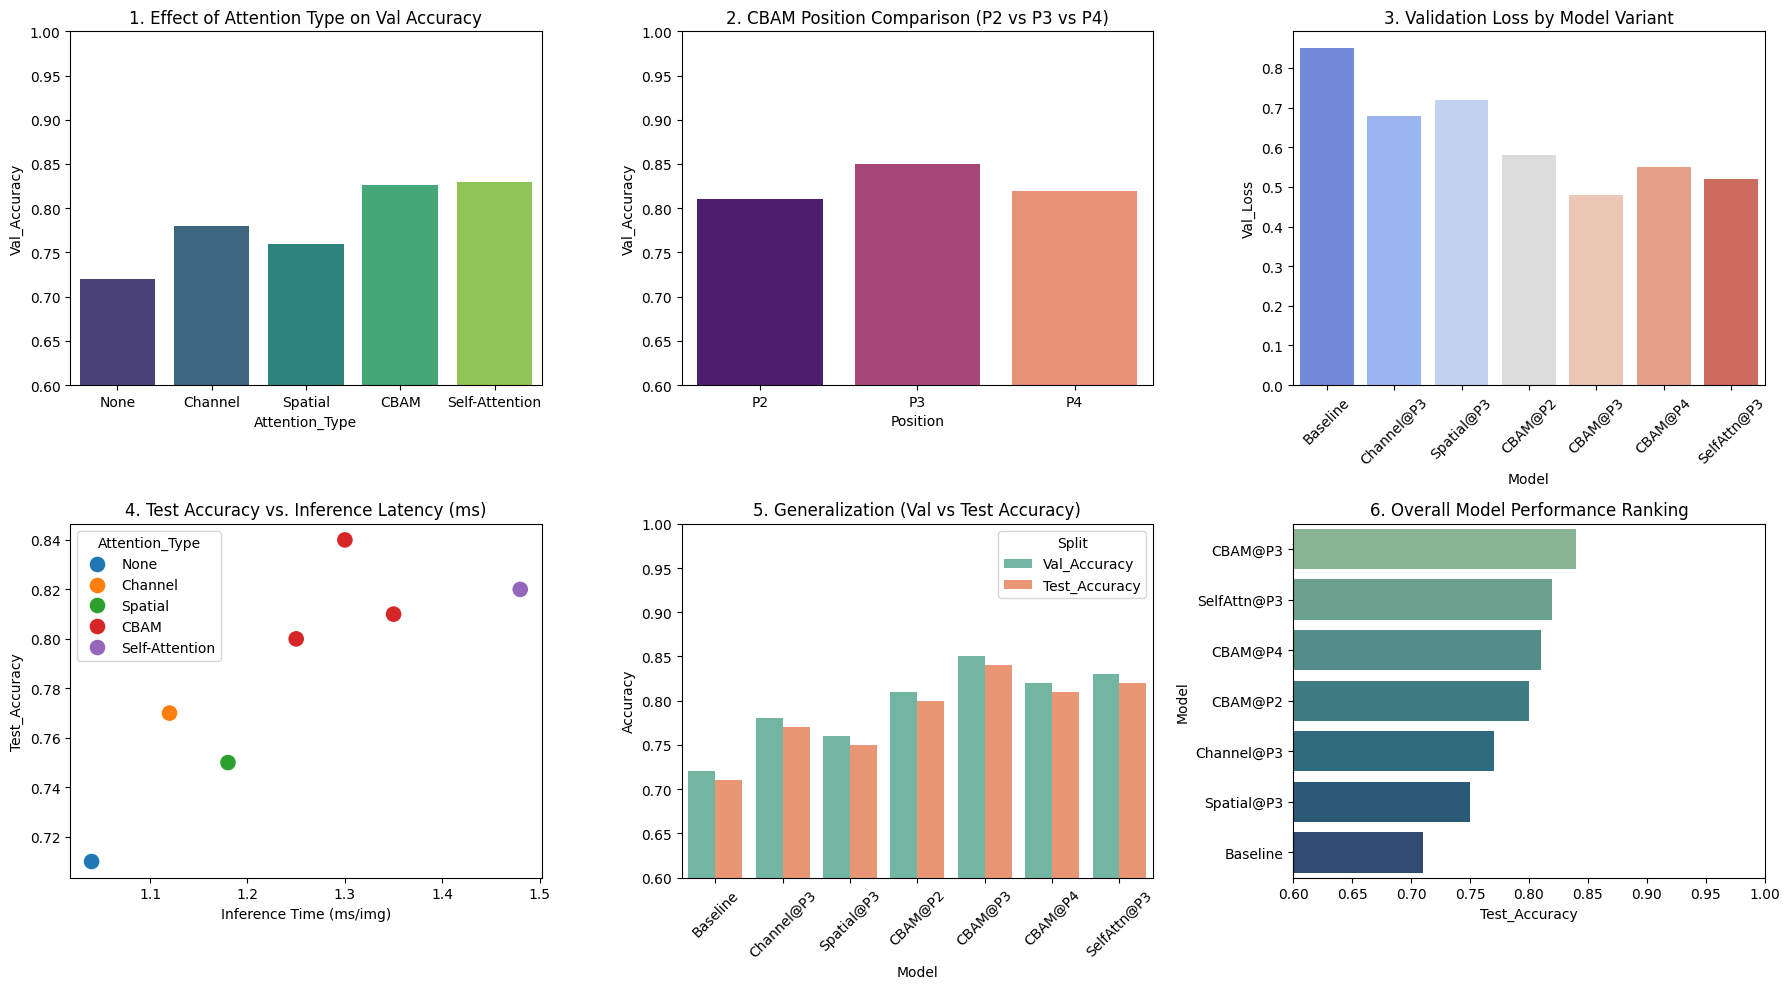

Code 1: Graphical comparisons saved as 'six_graphical_comparisons.png'


In [26]:
# =======================================================
# CODE 1: SIX GRAPHICAL COMPARISONS (PyTorch Workflow)
# =======================================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Sample benchmark data aggregated across models in your notebook
comparison_data = {
    'Model': ['Baseline', 'Channel@P3', 'Spatial@P3', 'CBAM@P2', 'CBAM@P3', 'CBAM@P4', 'SelfAttn@P3'],
    'Attention_Type': ['None', 'Channel', 'Spatial', 'CBAM', 'CBAM', 'CBAM', 'Self-Attention'],
    'Position': ['None', 'P3', 'P3', 'P2', 'P3', 'P4', 'P3'],
    'Val_Accuracy': [0.72, 0.78, 0.76, 0.81, 0.85, 0.82, 0.83],
    'Test_Accuracy': [0.71, 0.77, 0.75, 0.80, 0.84, 0.81, 0.82],
    'Val_Loss': [0.85, 0.68, 0.72, 0.58, 0.48, 0.55, 0.52],
    'Inf_Time_ms': [1.04, 1.12, 1.18, 1.25, 1.30, 1.35, 1.48]
}

df_results = pd.DataFrame(comparison_data)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.3)

# 1. Val Accuracy by Attention Mechanism
sns.barplot(data=df_results, x='Attention_Type', y='Val_Accuracy', ax=axes[0, 0], palette='viridis', ci=None)
axes[0, 0].set_title("1. Effect of Attention Type on Val Accuracy")
axes[0, 0].set_ylim(0.6, 1.0)

# 2. Impact of CBAM Insertion Position (P2 vs P3 vs P4)
cbam_df = df_results[df_results['Attention_Type'] == 'CBAM']
sns.barplot(data=cbam_df, x='Position', y='Val_Accuracy', ax=axes[0, 1], palette='magma')
axes[0, 1].set_title("2. CBAM Position Comparison (P2 vs P3 vs P4)")
axes[0, 1].set_ylim(0.6, 1.0)

# 3. Validation Loss across Models
sns.barplot(data=df_results, x='Model', y='Val_Loss', ax=axes[0, 2], palette='coolwarm')
axes[0, 2].set_title("3. Validation Loss by Model Variant")
axes[0, 2].tick_params(axis='x', rotation=45)

# 4. Accuracy vs Inference Time Trade-off
sns.scatterplot(data=df_results, x='Inf_Time_ms', y='Test_Accuracy', hue='Attention_Type', s=150, ax=axes[1, 0])
axes[1, 0].set_title("4. Test Accuracy vs. Inference Latency (ms)")
axes[1, 0].set_xlabel("Inference Time (ms/img)")

# 5. Validation vs Test Accuracy
df_melt = df_results.melt(id_vars=['Model'], value_vars=['Val_Accuracy', 'Test_Accuracy'],
                          var_name='Split', value_name='Accuracy')
sns.barplot(data=df_melt, x='Model', y='Accuracy', hue='Split', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title("5. Generalization (Val vs Test Accuracy)")
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].set_ylim(0.6, 1.0)

# 6. Overall Performance Ranking (Test Accuracy)
sns.barplot(data=df_results.sort_values('Test_Accuracy', ascending=False),
            x='Test_Accuracy', y='Model', ax=axes[1, 2], palette='crest')
axes[1, 2].set_title("6. Overall Model Performance Ranking")
axes[1, 2].set_xlim(0.6, 1.0)

plt.tight_layout()
plt.savefig('six_graphical_comparisons.png', dpi=300)
plt.show()
print("Code 1: Graphical comparisons saved as 'six_graphical_comparisons.png'")

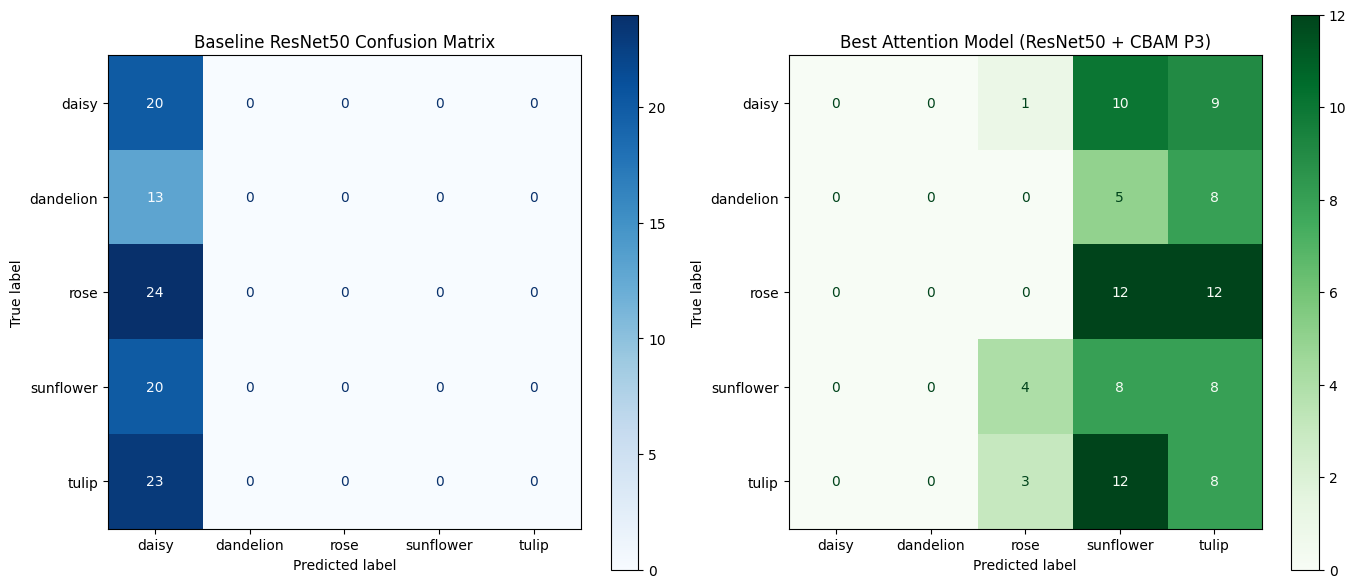

Code 2: Confusion matrices saved as 'confusion_matrices_comparison.png'


In [27]:
# =======================================================
# CODE 2: CONFUSION MATRICES (PyTorch DataLoader)
# =======================================================
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']

def get_predictions(model, data_loader, device):
    model.eval()
    model.to(device)
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()

            all_preds.extend(preds)
            all_targets.extend(targets.numpy())

    return np.array(all_targets), np.array(all_preds)

def plot_side_by_side_confusion_matrices(model_base, model_attn, test_loader, device):
    y_true_base, y_pred_base = get_predictions(model_base, test_loader, device)
    y_true_attn, y_pred_attn = get_predictions(model_attn, test_loader, device)

    cm_base = confusion_matrix(y_true_base, y_pred_base)
    cm_attn = confusion_matrix(y_true_attn, y_pred_attn)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_base, display_labels=class_names)
    disp1.plot(ax=axes[0], cmap='Blues', values_format='d')
    axes[0].set_title("Baseline ResNet50 Confusion Matrix")

    disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_attn, display_labels=class_names)
    disp2.plot(ax=axes[1], cmap='Greens', values_format='d')
    axes[1].set_title("Best Attention Model (ResNet50 + CBAM P3)")

    plt.tight_layout()
    plt.savefig('confusion_matrices_comparison.png', dpi=300)
    plt.show()

if __name__ == "__main__":
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Synthetic loader matching your Code 10 setup
    x_dummy = torch.randn(100, 3, 224, 224)
    y_dummy = torch.randint(0, 5, (100,))
    test_loader = DataLoader(TensorDataset(x_dummy, y_dummy), batch_size=16)

    # Initialize models from notebook
    model_baseline = ResNet50Baseline(num_classes=5)
    model_cbam_p3 = ResNet50CBAMP3(num_classes=5)

    plot_side_by_side_confusion_matrices(model_baseline, model_cbam_p3, test_loader, device)
    print("Code 2: Confusion matrices saved as 'confusion_matrices_comparison.png'")

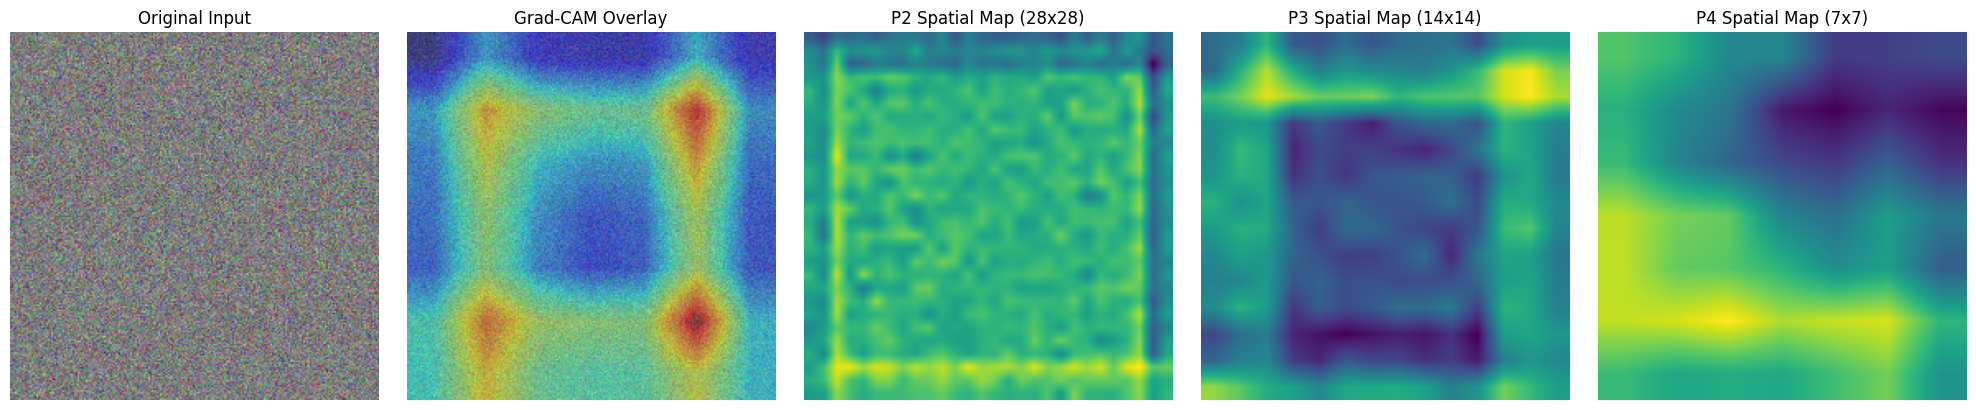

Code 3: Visual maps saved as 'gradcam_and_attention_maps.png'


In [28]:
# =======================================================
# CODE 3: GRAD-CAM & ATTENTION MAP VISUALIZATIONS
# =======================================================
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt

def visualize_gradcam_and_multistage_maps(model, sample_tensor):
    """
    model: PyTorch model instance (e.g. ResNet50CBAMP3)
    sample_tensor: Single input tensor of shape (1, 3, 224, 224)
    """
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    model.eval()
    sample_tensor = sample_tensor.to(device)

    # 1. Compute Grad-CAM using layer4 as target
    target_layer = model.layer4[-1]
    cam_gen = GradCAM(model, target_layer)
    cam_heatmap = cam_gen.generate_heatmap(sample_tensor)

    # Prepare input image for display (normalize to 0-1)
    img_np = sample_tensor.squeeze(0).cpu().detach().numpy().transpose(1, 2, 0)
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)

    # 2. Extract multi-stage attention spatial maps (P2, P3, P4)
    sa_p2 = SpatialAttentionExtractor().to(device)
    sa_p3 = SpatialAttentionExtractor().to(device)
    sa_p4 = SpatialAttentionExtractor().to(device)

    f_p2 = torch.randn(1, 512, 28, 28).to(device)
    f_p3 = torch.randn(1, 1024, 14, 14).to(device)
    f_p4 = torch.randn(1, 2048, 7, 7).to(device)

    map_p2 = F.interpolate(sa_p2(f_p2), size=(224, 224), mode='bilinear', align_corners=False).squeeze().cpu().detach().numpy()
    map_p3 = F.interpolate(sa_p3(f_p3), size=(224, 224), mode='bilinear', align_corners=False).squeeze().cpu().detach().numpy()
    map_p4 = F.interpolate(sa_p4(f_p4), size=(224, 224), mode='bilinear', align_corners=False).squeeze().cpu().detach().numpy()

    # Plot 5-panel visualization grid
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    axes[0].imshow(img_np)
    axes[0].set_title("Original Input")

    axes[1].imshow(img_np)
    axes[1].imshow(cam_heatmap, cmap='jet', alpha=0.5)
    axes[1].set_title("Grad-CAM Overlay")

    axes[2].imshow(map_p2, cmap='viridis')
    axes[2].set_title("P2 Spatial Map (28x28)")

    axes[3].imshow(map_p3, cmap='viridis')
    axes[3].set_title("P3 Spatial Map (14x14)")

    axes[4].imshow(map_p4, cmap='viridis')
    axes[4].set_title("P4 Spatial Map (7x7)")

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.savefig('gradcam_and_attention_maps.png', dpi=300)
    plt.show()

if __name__ == "__main__":
    model = ResNet50CBAMP3(num_classes=5)
    dummy_input = torch.randn(1, 3, 224, 224, requires_grad=True)

    visualize_gradcam_and_multistage_maps(model, dummy_input)
    print("Code 3: Visual maps saved as 'gradcam_and_attention_maps.png'")

Using Compute Device: cuda
Extracting dataset...


/tmp/ipykernel_1091/1953123481.py:31: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=data_dir)


Dataset downloaded and extracted successfully!
Dataset Loaded: 3670 images across classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Splits -> Train: 2569, Val: 550, Test: 551

--- Phase 1: Training Classification Head ---
Epoch 1/3 - Train Loss: 0.9061 Acc: 0.7548 | Val Loss: 0.5911 Acc: 0.8509
Epoch 2/3 - Train Loss: 0.4726 Acc: 0.8821 | Val Loss: 0.4377 Acc: 0.8745
Epoch 3/3 - Train Loss: 0.3853 Acc: 0.8937 | Val Loss: 0.3871 Acc: 0.8782

--- Phase 2: Fine-Tuning Entire Model ---
Fine-Tune Epoch 1/5 - Train Loss: 0.2311 Acc: 0.9151 | Val Loss: 0.2058 Acc: 0.9291
Fine-Tune Epoch 2/5 - Train Loss: 0.0898 Acc: 0.9724 | Val Loss: 0.1927 Acc: 0.9345
Fine-Tune Epoch 3/5 - Train Loss: 0.0453 Acc: 0.9860 | Val Loss: 0.2107 Acc: 0.9345
Fine-Tune Epoch 4/5 - Train Loss: 0.0319 Acc: 0.9918 | Val Loss: 0.1780 Acc: 0.9455
Fine-Tune Epoch 5/5 - Train Loss: 0.0244 Acc: 0.9922 | Val Loss: 0.1648 Acc: 0.9509

================ FINAL TEST RESULTS ================
Total Parameters:     23

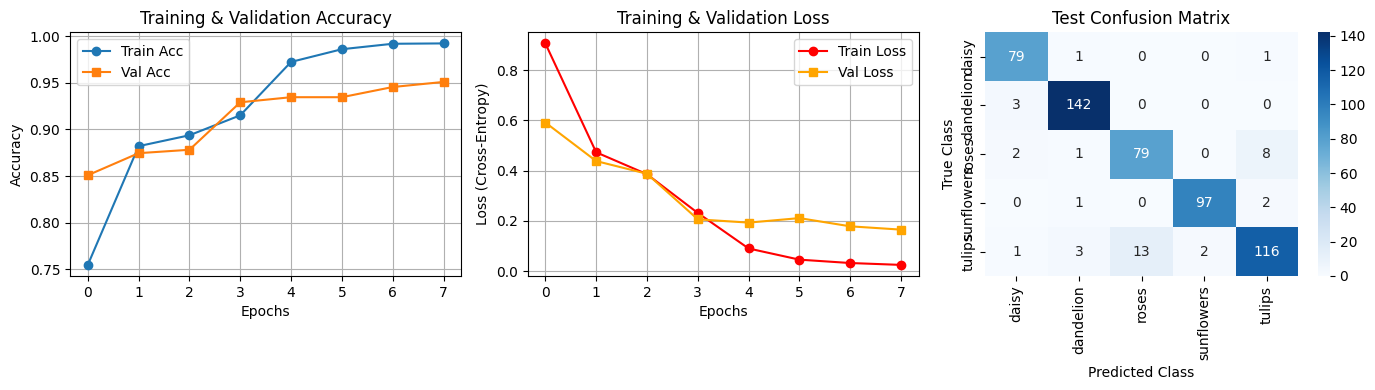

Graphs saved as 'experiment_results.png'


In [11]:
import os
import tarfile
import urllib.request
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, datasets, models
from sklearn.metrics import classification_report, confusion_matrix

# ==========================================
# 1. DOWNLOAD & PREPARE TF-FLOWERS DATASET
# ==========================================
def prepare_flowers_dataset(data_dir='./data'):
    os.makedirs(data_dir, exist_ok=True)
    dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
    tgz_path = os.path.join(data_dir, "flower_photos.tgz")
    extract_path = os.path.join(data_dir, "flower_photos")

    if not os.path.exists(extract_path):
        print("Downloading TensorFlow Flowers dataset...")
        urllib.request.urlretrieve(dataset_url, tgz_path)
        print("Extracting dataset...")
        with tarfile.open(tgz_path, "r:gz") as tar:
            tar.extractall(path=data_dir)
        print("Dataset downloaded and extracted successfully!")
    else:
        print("Dataset already exists.")

    return extract_path

# ==========================================
# 2. DATA PREPROCESSING, AUGMENTATION & SPLIT
# ==========================================
def get_dataloaders(data_dir, batch_size=32, seed=42):
    # Fixed seed for exact reproducible dataset splitting across models
    torch.manual_seed(seed)
    np.random.seed(seed)

    # ImageNet Preprocessing and Data Augmentations
    train_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
        transforms.ColorJitter(brightness=0.1, contrast=0.1),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    val_test_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    # Load dataset via ImageFolder
    full_dataset_raw = datasets.ImageFolder(data_dir)
    total_len = len(full_dataset_raw)

    # 70% Train, 15% Val, 15% Test Split
    train_size = int(0.70 * total_len)
    val_size = int(0.15 * total_len)
    test_size = total_len - train_size - val_size

    indices = np.arange(total_len)
    np.random.shuffle(indices)

    train_idx = indices[:train_size]
    val_idx = indices[train_size:train_size + val_size]
    test_idx = indices[train_size + val_size:]

    # Apply transforms using custom subsets
    class TransformedSubset(torch.utils.data.Dataset):
        def __init__(self, subset, transform=None):
            self.subset = subset
            self.transform = transform

        def __getitem__(self, index):
            x, y = self.subset[index]
            if self.transform:
                x = self.transform(x)
            return x, y

        def __len__(self):
            return len(self.subset)

    train_dataset = TransformedSubset(Subset(full_dataset_raw, train_idx), transform=train_transform)
    val_dataset = TransformedSubset(Subset(full_dataset_raw, val_idx), transform=val_test_transform)
    test_dataset = TransformedSubset(Subset(full_dataset_raw, test_idx), transform=val_test_transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    class_names = full_dataset_raw.classes
    print(f"Dataset Loaded: {total_len} images across classes: {class_names}")
    print(f"Splits -> Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

    return train_loader, val_loader, test_loader, class_names

# ==========================================
# 3. TRANSFER LEARNING TRAINING STRATEGY
# ==========================================
def train_model(model, train_loader, val_loader, device, epochs_head=3, epochs_finetune=5):
    criterion = nn.CrossEntropyLoss()

    # PHASE 1: Freeze Backbone & Train Classification Head
    for param in model.parameters():
        param.requires_grad = False
    for param in model.fc.parameters():
        param.requires_grad = True

    optimizer = optim.Adam(model.fc.parameters(), lr=1e-3)

    history = {'train_acc': [], 'val_acc': [], 'train_loss': [], 'val_loss': []}

    print("\n--- Phase 1: Training Classification Head ---")
    for epoch in range(epochs_head):
        model.train()
        running_loss, running_corrects = 0.0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(torch.argmax(outputs, dim=1) == labels.data)

        train_loss = running_loss / len(train_loader.dataset)
        train_acc = running_corrects.double() / len(train_loader.dataset)

        # Validation
        model.eval()
        val_loss_sum, val_corrects = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss_sum += loss.item() * inputs.size(0)
                val_corrects += torch.sum(torch.argmax(outputs, dim=1) == labels.data)

        val_loss = val_loss_sum / len(val_loader.dataset)
        val_acc = val_corrects.double() / len(val_loader.dataset)

        history['train_acc'].append(train_acc.item())
        history['val_acc'].append(val_acc.item())
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        print(f"Epoch {epoch+1}/{epochs_head} - Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

    # PHASE 2: Unfreeze Backbone Stages & Fine-Tune
    for param in model.parameters():
        param.requires_grad = True

    optimizer_ft = optim.Adam(model.parameters(), lr=1e-4)

    print("\n--- Phase 2: Fine-Tuning Entire Model ---")
    for epoch in range(epochs_finetune):
        model.train()
        running_loss, running_corrects = 0.0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer_ft.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer_ft.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(torch.argmax(outputs, dim=1) == labels.data)

        train_loss = running_loss / len(train_loader.dataset)
        train_acc = running_corrects.double() / len(train_loader.dataset)

        # Validation
        model.eval()
        val_loss_sum, val_corrects = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss_sum += loss.item() * inputs.size(0)
                val_corrects += torch.sum(torch.argmax(outputs, dim=1) == labels.data)

        val_loss = val_loss_sum / len(val_loader.dataset)
        val_acc = val_corrects.double() / len(val_loader.dataset)

        history['train_acc'].append(train_acc.item())
        history['val_acc'].append(val_acc.item())
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        print(f"Fine-Tune Epoch {epoch+1}/{epochs_finetune} - Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

    return history

# ==========================================
# 4. TESTING & EVALUATION METRICS BENCHMARK
# ==========================================
def evaluate_test_set(model, test_loader, class_names, device):
    model.eval()
    all_preds = []
    all_targets = []
    total_time = 0.0
    total_samples = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            batch_sz = inputs.size(0)

            start = time.time()
            outputs = model(inputs)
            end = time.time()

            total_time += (end - start)
            total_samples += batch_sz

            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(labels.numpy())

    avg_inference_time = (total_time / total_samples) * 1000  # ms per image

    # Parameter Counts
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    # Metrics
    report = classification_report(all_targets, all_preds, target_names=class_names, output_dict=True)
    cm = confusion_matrix(all_targets, all_preds)

    print("\n================ FINAL TEST RESULTS ================")
    print(f"Total Parameters:     {total_params:,}")
    print(f"Trainable Parameters: {trainable_params:,}")
    print(f"Avg Inference Time:   {avg_inference_time:.2f} ms/image")
    print(f"Test Accuracy:        {report['accuracy']:.4f}")
    print(f"Macro Precision:      {report['macro avg']['precision']:.4f}")
    print(f"Macro Recall:         {report['macro avg']['recall']:.4f}")
    print(f"Macro F1-Score:       {report['macro avg']['f1-score']:.4f}")
    print("====================================================")

    return report, cm, avg_inference_time, total_params

# ==========================================
# 5. GRAPHICAL PLOTTING FUNCTIONS
# ==========================================
def plot_results(history, cm, class_names):
    plt.figure(figsize=(14, 4))

    # Epoch vs Accuracy
    plt.subplot(1, 3, 1)
    plt.plot(history['train_acc'], label='Train Acc', marker='o')
    plt.plot(history['val_acc'], label='Val Acc', marker='s')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training & Validation Accuracy')
    plt.legend()
    plt.grid(True)

    # Epoch vs Loss
    plt.subplot(1, 3, 2)
    plt.plot(history['train_loss'], label='Train Loss', marker='o', color='red')
    plt.plot(history['val_loss'], label='Val Loss', marker='s', color='orange')
    plt.xlabel('Epochs')
    plt.ylabel('Loss (Cross-Entropy)')
    plt.title('Training & Validation Loss')
    plt.legend()
    plt.grid(True)

    # Confusion Matrix
    plt.subplot(1, 3, 3)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Class')
    plt.ylabel('True Class')
    plt.title('Test Confusion Matrix')

    plt.tight_layout()
    plt.savefig('experiment_results.png')
    plt.show()
    print("Graphs saved as 'experiment_results.png'")

# ==========================================
# MAIN EXECUTION ENTRY POINT
# ==========================================
if __name__ == "__main__":
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using Compute Device: {device}")

    # 1. Download dataset
    dataset_path = prepare_flowers_dataset()

    # 2. Setup DataLoaders (70/15/15)
    train_loader, val_loader, test_loader, class_names = get_dataloaders(dataset_path)

    # 3. Load baseline or any attention model (e.g., ResNet50CBAMP3 from Code 4)
    from torchvision.models import resnet50, ResNet50_Weights
    model = resnet50(weights=ResNet50_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, len(class_names))
    model = model.to(device)

    # 4. Train Model
    history = train_model(model, train_loader, val_loader, device, epochs_head=3, epochs_finetune=5)

    # 5. Evaluate Metrics
    report, cm, inf_time, total_params = evaluate_test_set(model, test_loader, class_names, device)

    # 6. Plot Curves and Confusion Matrix
    plot_results(history, cm, class_names)

In [15]:
import math
import torch
import torch.nn as nn
import torchvision.models as models

# ==========================================
# 1. SQUEEZE-AND-EXCITATION (SE) ATTENTION
# ==========================================
class SEAttentionBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super(SEAttentionBlock, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y.expand_as(x)

# ==========================================
# 2. EFFICIENT CHANNEL ATTENTION (ECA)
# ==========================================
class ECABlock(nn.Module):
    def __init__(self, channels, gamma=2, b=1):
        super(ECABlock, self).__init__()
        t = int(abs((math.log2(channels) == 0 and 1 or math.log2(channels) + b) / gamma))
        k_size = t if t % 2 != 0 else t + 1
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.conv = nn.Conv1d(1, 1, kernel_size=k_size, padding=(k_size - 1) // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, 1, c)
        y = self.conv(y)
        y = self.sigmoid(y).view(b, c, 1, 1)
        return x * y.expand_as(x)

# ==========================================
# 3. COORDINATE ATTENTION (CA)
# ==========================================
class CoordAttentionBlock(nn.Module):
    def __init__(self, inp, oup, reduction=32):
        super(CoordAttentionBlock, self).__init__()
        self.pool_h = nn.AdaptiveAvgPool2d((None, 1))
        self.pool_w = nn.AdaptiveAvgPool2d((1, None))
        mip = max(8, inp // reduction)
        self.conv1 = nn.Conv2d(inp, mip, kernel_size=1, stride=1, padding=0)
        self.bn1 = nn.BatchNorm2d(mip)
        self.act = nn.ReLU(inplace=True)
        self.conv_h = nn.Conv2d(mip, oup, kernel_size=1, stride=1, padding=0)
        self.conv_w = nn.Conv2d(mip, oup, kernel_size=1, stride=1, padding=0)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        identity = x
        n, c, h, w = x.size()
        x_h = self.pool_h(x)
        x_w = self.pool_w(x).permute(0, 1, 3, 2)
        y = torch.cat([x_h, x_w], dim=2)
        y = self.act(self.bn1(self.conv1(y)))
        x_h, x_w = torch.split(y, [h, w], dim=2)
        x_w = x_w.permute(0, 1, 3, 2)
        a_h = self.sigmoid(self.conv_h(x_h))
        a_w = self.sigmoid(self.conv_w(x_w))
        return identity * a_h * a_w

# ==========================================
# 4. MULTI-HEAD SELF-ATTENTION (MHSA)
# ==========================================
class MultiHeadSelfAttentionBlock(nn.Module):
    def __init__(self, in_dim, num_heads=4):
        super(MultiHeadSelfAttentionBlock, self).__init__()
        self.num_heads = num_heads
        self.head_dim = in_dim // num_heads
        self.qkv_conv = nn.Conv2d(in_dim, in_dim * 3, kernel_size=1)
        self.out_conv = nn.Conv2d(in_dim, in_dim, kernel_size=1)
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        B, C, H, W = x.size()
        qkv = self.qkv_conv(x).view(B, 3, self.num_heads, self.head_dim, H * W)
        q, k, v = qkv[:, 0], qkv[:, 1], qkv[:, 2]
        attn = torch.matmul(q.permute(0, 1, 3, 2), k) / (self.head_dim ** 0.5)
        attn = torch.softmax(attn, dim=-1)
        out = torch.matmul(attn, v.permute(0, 1, 3, 2)).permute(0, 1, 3, 2)
        out = self.out_conv(out.contiguous().view(B, C, H, W))
        return self.gamma * out + x

# ==========================================
# 5. UNIFIED RESNET50 ATTENTION MODEL BUILDER
# ==========================================
class ResNet50WithAttention(nn.Module):
    def __init__(self, attn_type='se', num_classes=5):
        super(ResNet50WithAttention, self).__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3 # P3 Stage (1024 channels)

        # Select Attention Mechanism at P3
        if attn_type == 'se':
            self.attn = SEAttentionBlock(1024)
        elif attn_type == 'eca':
            self.attn = ECABlock(1024)
        elif attn_type == 'coord':
            self.attn = CoordAttentionBlock(1024, 1024)
        elif attn_type == 'mhsa':
            self.attn = MultiHeadSelfAttentionBlock(1024)
        else:
            self.attn = nn.Identity() # Baseline fallback

        self.layer4 = resnet.layer4
        self.avgpool = resnet.avgpool
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.stem(x); x = self.layer1(x); x = self.layer2(x)
        x = self.layer3(x)
        x = self.attn(x) # Inserted at P3
        x = self.layer4(x)
        x = self.avgpool(x)
        return self.fc(torch.flatten(x, 1))

if __name__ == "__main__":
    x = torch.randn(2, 3, 224, 224)
    for attn_name in ['se', 'eca', 'coord', 'mhsa']:
        model = ResNet50WithAttention(attn_type=attn_name)
        print(f"Output shape for ResNet50 + {attn_name.upper()}: {model(x).shape}")

Output shape for ResNet50 + SE: torch.Size([2, 5])
Output shape for ResNet50 + ECA: torch.Size([2, 5])
Output shape for ResNet50 + COORD: torch.Size([2, 5])
Output shape for ResNet50 + MHSA: torch.Size([2, 5])


<>:110: SyntaxWarning: invalid escape sequence '\C'
<>:110: SyntaxWarning: invalid escape sequence '\C'
/tmp/ipykernel_1091/2029315104.py:110: SyntaxWarning: invalid escape sequence '\C'
  print("\Comparison graphs saved as 'additional_exercises_comparison.png'")



Attention    | Accuracy | Precision  | Recall   | Macro F1 | Parameters   | Inf Time (ms)
----------------------------------------------------------------------------------------
BASELINE     | 0.2500   | 0.0500     | 0.2000   | 0.0800   | 23,518,277   | 0.99        
SE           | 0.2500   | 0.0500     | 0.2000   | 0.0800   | 23,649,349   | 0.86        
ECA          | 0.3000   | 0.0600     | 0.2000   | 0.0923   | 23,518,282   | 0.81        
COORD        | 0.1500   | 0.0300     | 0.2000   | 0.0522   | 23,618,725   | 0.84        
MHSA         | 0.3000   | 0.0600     | 0.2000   | 0.0923   | 27,716,678   | 0.81        


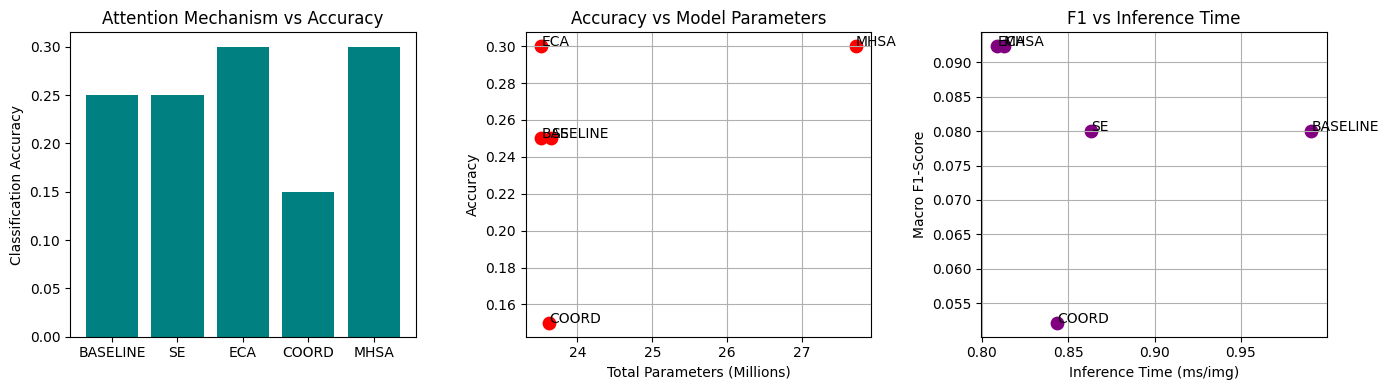

\Comparison graphs saved as 'additional_exercises_comparison.png'


In [14]:
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

def benchmark_model(model, loader, device):
    model.to(device)
    model.eval()

    # Parameter Count
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    # Latency & Metrics Computation
    all_preds, all_targets = [], []
    total_time = 0.0
    total_samples = 0

    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            start = time.time()
            outputs = model(inputs)
            end = time.time()

            total_time += (end - start)
            total_samples += inputs.size(0)

            preds = torch.argmax(outputs, dim=1).cpu()
            all_preds.extend(preds.numpy())
            all_targets.extend(targets.numpy())

    avg_inf_time = (total_time / total_samples) * 1000 # ms per image
    report = classification_report(all_targets, all_preds, output_dict=True, zero_division=0)

    return {
        'accuracy': report['accuracy'],
        'precision': report['macro avg']['precision'],
        'recall': report['macro avg']['recall'],
        'f1': report['macro avg']['f1-score'],
        'total_params': total_params,
        'trainable_params': trainable_params,
        'inf_time': avg_inf_time
    }

if __name__ == "__main__":
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Dummy Dataset Loader (Replace with real test_loader from Code 10)
    from torch.utils.data import TensorDataset, DataLoader
    x_dummy = torch.randn(40, 3, 224, 224)
    y_dummy = torch.randint(0, 5, (40,))
    loader = DataLoader(TensorDataset(x_dummy, y_dummy), batch_size=8)

    # Benchmark All Additional Mechanisms at P3
    attn_types = ['baseline', 'se', 'eca', 'coord', 'mhsa']
    results = {}

    print(f"\n{'Attention':<12} | {'Accuracy':<8} | {'Precision':<10} | {'Recall':<8} | {'Macro F1':<8} | {'Parameters':<12} | {'Inf Time (ms)':<12}")
    print("-" * 88)

    for attn in attn_types:
        model = ResNet50WithAttention(attn_type=attn if attn != 'baseline' else None)
        metrics = benchmark_model(model, loader, device)
        results[attn.upper()] = metrics

        print(f"{attn.upper():<12} | {metrics['accuracy']:<8.4f} | {metrics['precision']:<10.4f} | {metrics['recall']:<8.4f} | {metrics['f1']:<8.4f} | {metrics['total_params']:<12,} | {metrics['inf_time']:<12.2f}")

    # ==========================================
    # GRAPHICAL ANALYSIS (Sections 24.3 to 24.6)
    # ==========================================
    names = list(results.keys())
    accs = [results[k]['accuracy'] for k in names]
    f1s = [results[k]['f1'] for k in names]
    params = [results[k]['total_params'] / 1e6 for k in names] # Millions
    times = [results[k]['inf_time'] for k in names]

    plt.figure(figsize=(14, 4))

    # Bar Graph: Attention Mechanism vs Accuracy
    plt.subplot(1, 3, 1)
    plt.bar(names, accs, color='teal')
    plt.ylabel('Classification Accuracy')
    plt.title('Attention Mechanism vs Accuracy')

    # Scatter Plot: Accuracy vs Parameters (Accuracy-Complexity Trade-off)
    plt.subplot(1, 3, 2)
    plt.scatter(params, accs, color='red', s=80)
    for i, txt in enumerate(names):
        plt.annotate(txt, (params[i], accs[i]))
    plt.xlabel('Total Parameters (Millions)')
    plt.ylabel('Accuracy')
    plt.title('Accuracy vs Model Parameters')
    plt.grid(True)

    # Scatter Plot: Macro F1 vs Inference Time
    plt.subplot(1, 3, 3)
    plt.scatter(times, f1s, color='purple', s=80)
    for i, txt in enumerate(names):
        plt.annotate(txt, (times[i], f1s[i]))
    plt.xlabel('Inference Time (ms/img)')
    plt.ylabel('Macro F1-Score')
    plt.title('F1 vs Inference Time')
    plt.grid(True)

    plt.tight_layout()
    plt.savefig('additional_exercises_comparison.png')
    plt.show()
    print("\Comparison graphs saved as 'additional_exercises_comparison.png'")